In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier , plot_tree, DecisionTreeRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression, Lasso, Ridge
from sklearn.neighbors import KNeighborsClassifier , KNeighborsRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor

from sklearn.metrics import accuracy_score, r2_score


from tqdm import tqdm 


from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings("ignore")
import os 
os.chdir('E:\Backup Files Abhinav_Satyam\Practical Machine Learning\Sanjay Sir Git Repo\Datasets\Cases\Concrete_Strength')

In [4]:
conc_data = pd.read_csv('Concrete_Data.csv')
conc_data

,Cement,Blast,Fly,Water,Superplasticizer,Coarse,Fine,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30
...,...,...,...,...,...,...,...,...,...
1025,276.4,116.0,90.3,179.6,8.9,870.1,768.3,28,44.28
1026,322.2,0.0,115.6,196.0,10.4,817.9,813.4,28,31.18
1027,148.5,139.4,108.6,192.7,6.1,892.4,780.0,28,23.70
1028,159.1,186.7,0.0,175.6,11.3,989.6,788.9,28,32.77


In [8]:
X,y = conc_data.drop('Strength', axis = 1) , conc_data['Strength']

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.3, random_state=26)

In [10]:
m_feat = [2,3,4,5]
n_samples = [25,50,100]
scores = []
for m in m_feat:
    for n in n_samples:
        rf = RandomForestRegressor(max_features=m, n_estimators=n,random_state=26)

        rf.fit(X_train, y_train)
        y_pred = rf.predict(X_test)
        scores.append([m, n , r2_score(y_test, y_pred)])

df_scores = pd.DataFrame(scores, columns=['Features','n','Score'])
df_scores.sort_values(by='Score',ascending=False)

,Features,n,Score
8,4,100,0.892511
11,5,100,0.892347
4,3,50,0.889646
7,4,50,0.889587
5,3,100,0.889134
6,4,25,0.888983
10,5,50,0.888295
9,5,25,0.885371
3,3,25,0.884090
0,2,25,0.875060


In [15]:
X.columns

Index(['Cement', 'Blast', 'Fly', 'Water', 'Superplasticizer', 'Coarse', 'Fine',
       'Age'],
      dtype='str')

In [14]:
bestTree = RandomForestRegressor(max_features=4, n_estimators=100,random_state=26)
 
bestTree.fit(X_train , y_train)
bestTree.feature_importances_


array([0.24453335, 0.05750368, 0.03800992, 0.14507907, 0.07696752,
       0.04250447, 0.06287755, 0.33252443])

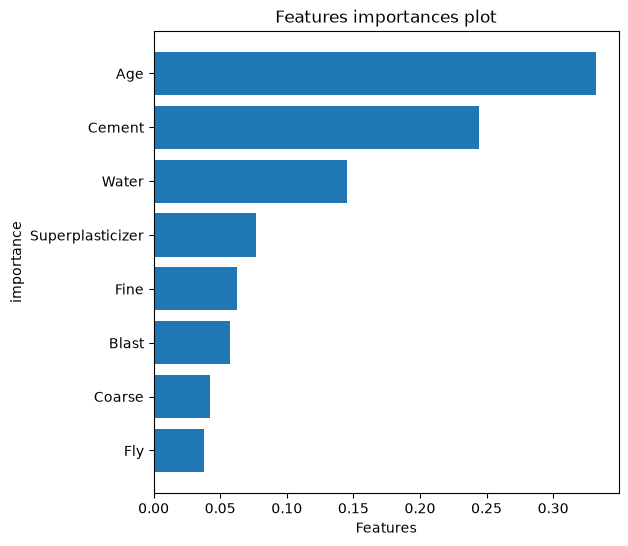

In [11]:
 

bestTree = RandomForestRegressor(max_features=4, n_estimators=100,random_state=26)
 
bestTree.fit(X_train , y_train)

df_imp = pd.DataFrame({'features':list(X_train.columns),
                          'importance': bestTree.feature_importances_})

df_imp.sort_values('importance',inplace=True)
plt.figure(figsize=(6,6))
plt.barh(df_imp['features'], df_imp['importance'])
plt.xlabel('Features')
plt.ylabel('importance')
plt.title('Features importances plot')

plt.show()